
### importing the nessecary libs:

In [2]:
import pandas as pd
import numpy as np
import missingno as msno
import matplotlib.pyplot as plt
import seaborn as sns
from data_profiling import ProfileReport
from pathlib import Path

### getting the data from kaggle

In [3]:
ROOT = Path().cwd().parent
dataset = ROOT / "data" / "raw" / "student-mental.csv"

In [4]:
print("Path to dataset files:", dataset,",exist :",dataset.exists())

Path to dataset files: c:\Users\Youcode\Documents\DEV_AI\sprint_1\soutnance_1\data\raw\student-mental.csv ,exist : True


### Chargement et première inspection


In [5]:
df = pd.read_csv(dataset)
print(df.shape)
print(df.dtypes)
display(df.head())

(2000, 17)
Student_ID                         object
Age                                 int64
Gender                             object
Year_of_Study                       int64
Sleep_Hours                       float64
Study_Hours_Per_Week              float64
GPA                               float64
Social_Media_Hours                float64
Screen_Time_Hours                 float64
Physical_Activity                  object
Financial_Stress                  float64
Family_Support                    float64
Attendance_Rate                   float64
Part_Time_Job                      object
Diet_Quality                       object
Previous_Mental_Health_History     object
Mental_Health_Risk                 object
dtype: object


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


### Statistiques descriptives


In [43]:
print("Duplicate rows:", df.duplicated().sum())                   # 0
print("Rows with missing values:", df.isna().any(axis=1).sum())  # 394

Duplicate rows: 0
Rows with missing values: 394


In [6]:
display(df.describe(include="all").T )# transpose
categories = df.select_dtypes(include="object")
for categorie in categories:
    if categorie != "Student_ID":
        display(df[categorie].value_counts(normalize=True))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Student_ID,2000,2000,STU0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,2000.0,NaN,NaN,NaN,21.1315,2.139275,17.0,20.0,21.0,23.0,29.0
Gender,2000,3,Female,971,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year_of_Study,2000.0,NaN,NaN,NaN,2.63,1.316802,1.0,1.0,2.0,4.0,5.0
Sleep_Hours,1938.0,NaN,NaN,NaN,6.758875,1.127072,3.3,6.0,6.7,7.6,10.0
Study_Hours_Per_Week,2000.0,NaN,NaN,NaN,19.9979,5.719274,2.4,16.0,19.8,24.0,38.3
GPA,1962.0,NaN,NaN,NaN,2.562503,0.343993,1.5,2.32,2.56,2.79,3.66
Social_Media_Hours,1942.0,NaN,NaN,NaN,6.013955,1.153422,2.1,5.225,6.0,6.7,10.0
Screen_Time_Hours,2000.0,NaN,NaN,NaN,8.5485,1.657571,3.3,7.4,8.5,9.7,14.0
Physical_Activity,2000,3,Moderate,906,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Gender
Female        0.4855
Male          0.4660
Non-binary    0.0485
Name: proportion, dtype: float64

Physical_Activity
Moderate    0.4530
Low         0.3395
High        0.2075
Name: proportion, dtype: float64

Part_Time_Job
No     0.6445
Yes    0.3555
Name: proportion, dtype: float64

Diet_Quality
Average    0.445365
Poor       0.303988
Good       0.250647
Name: proportion, dtype: float64

Previous_Mental_Health_History
No     0.704
Yes    0.296
Name: proportion, dtype: float64

Mental_Health_Risk
High      0.34
Medium    0.33
Low       0.33
Name: proportion, dtype: float64

### Visualisation des valeurs manquantes


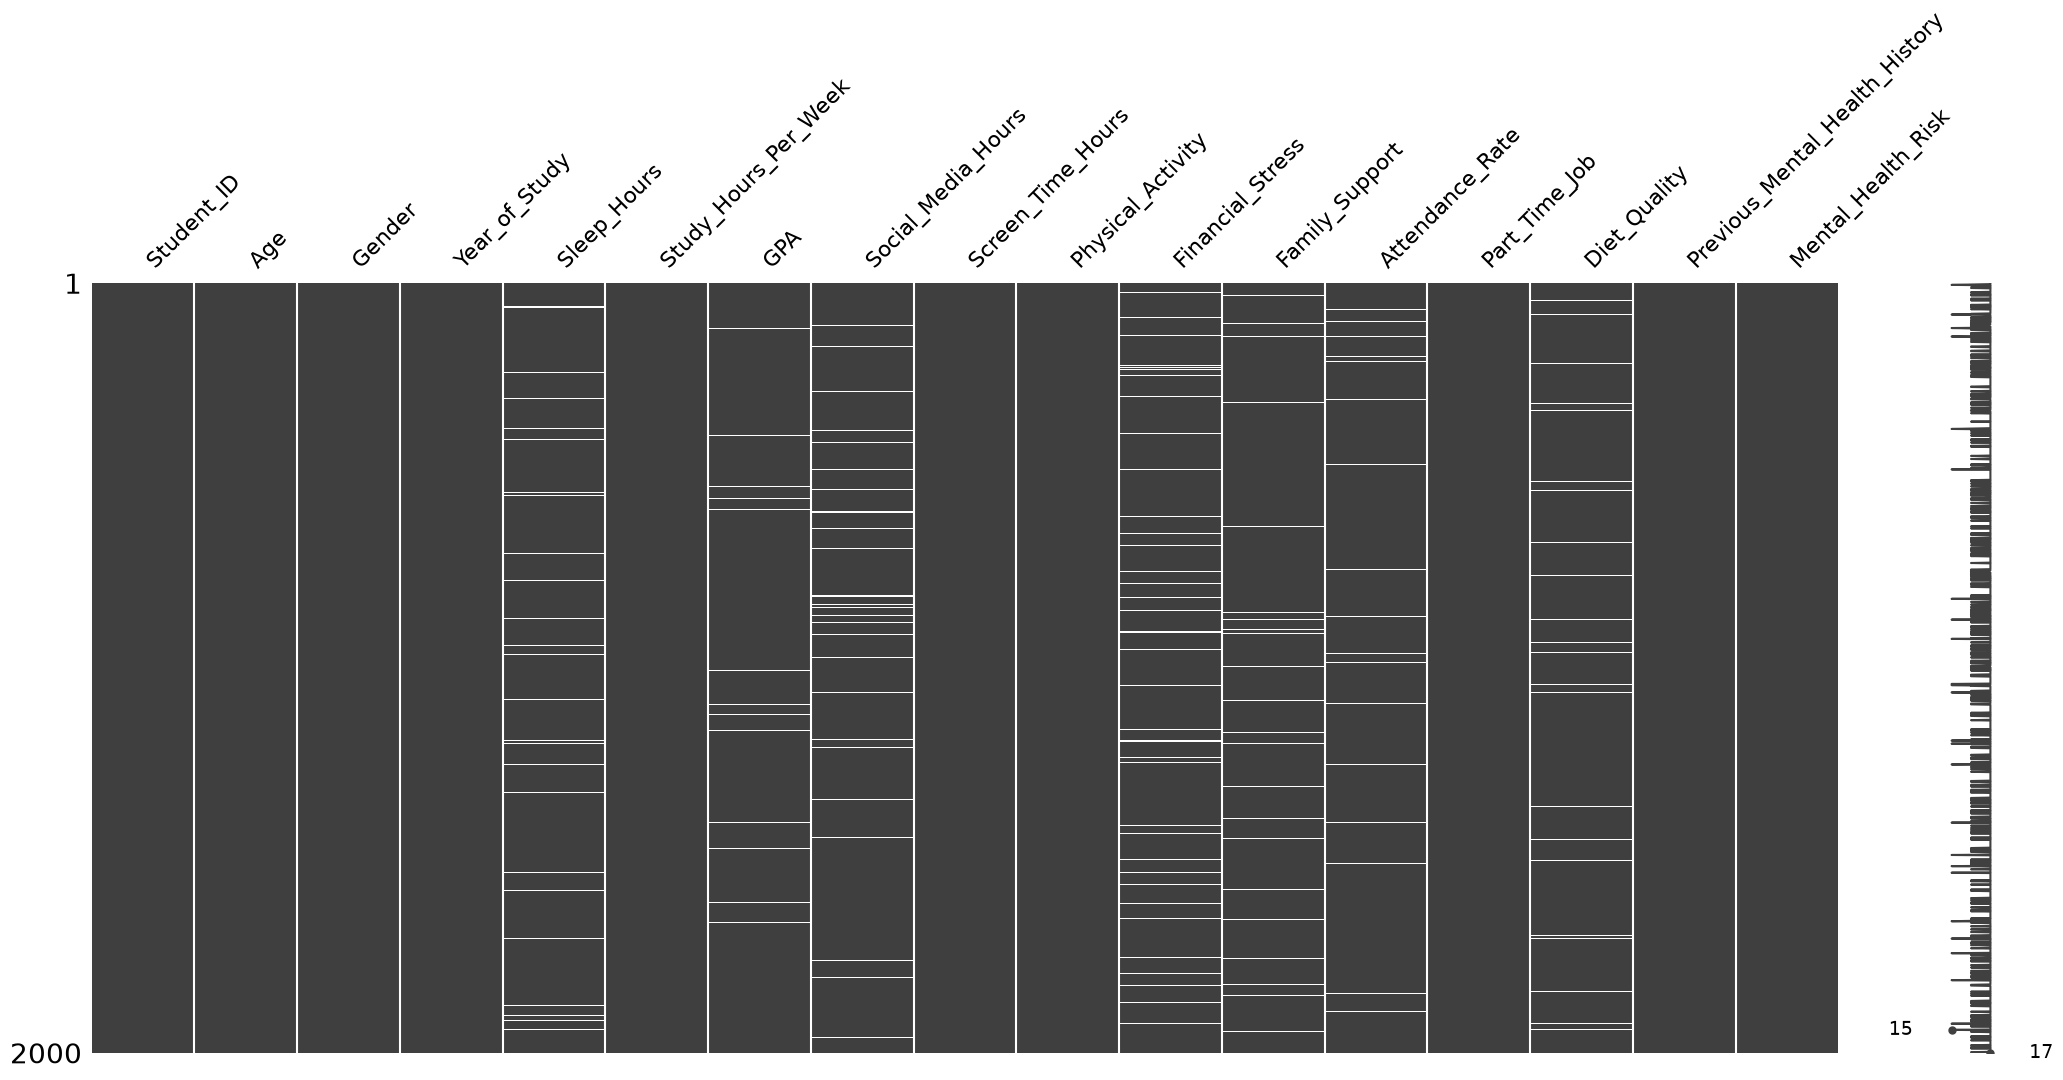

In [7]:
msno.matrix(df)
plt.show()

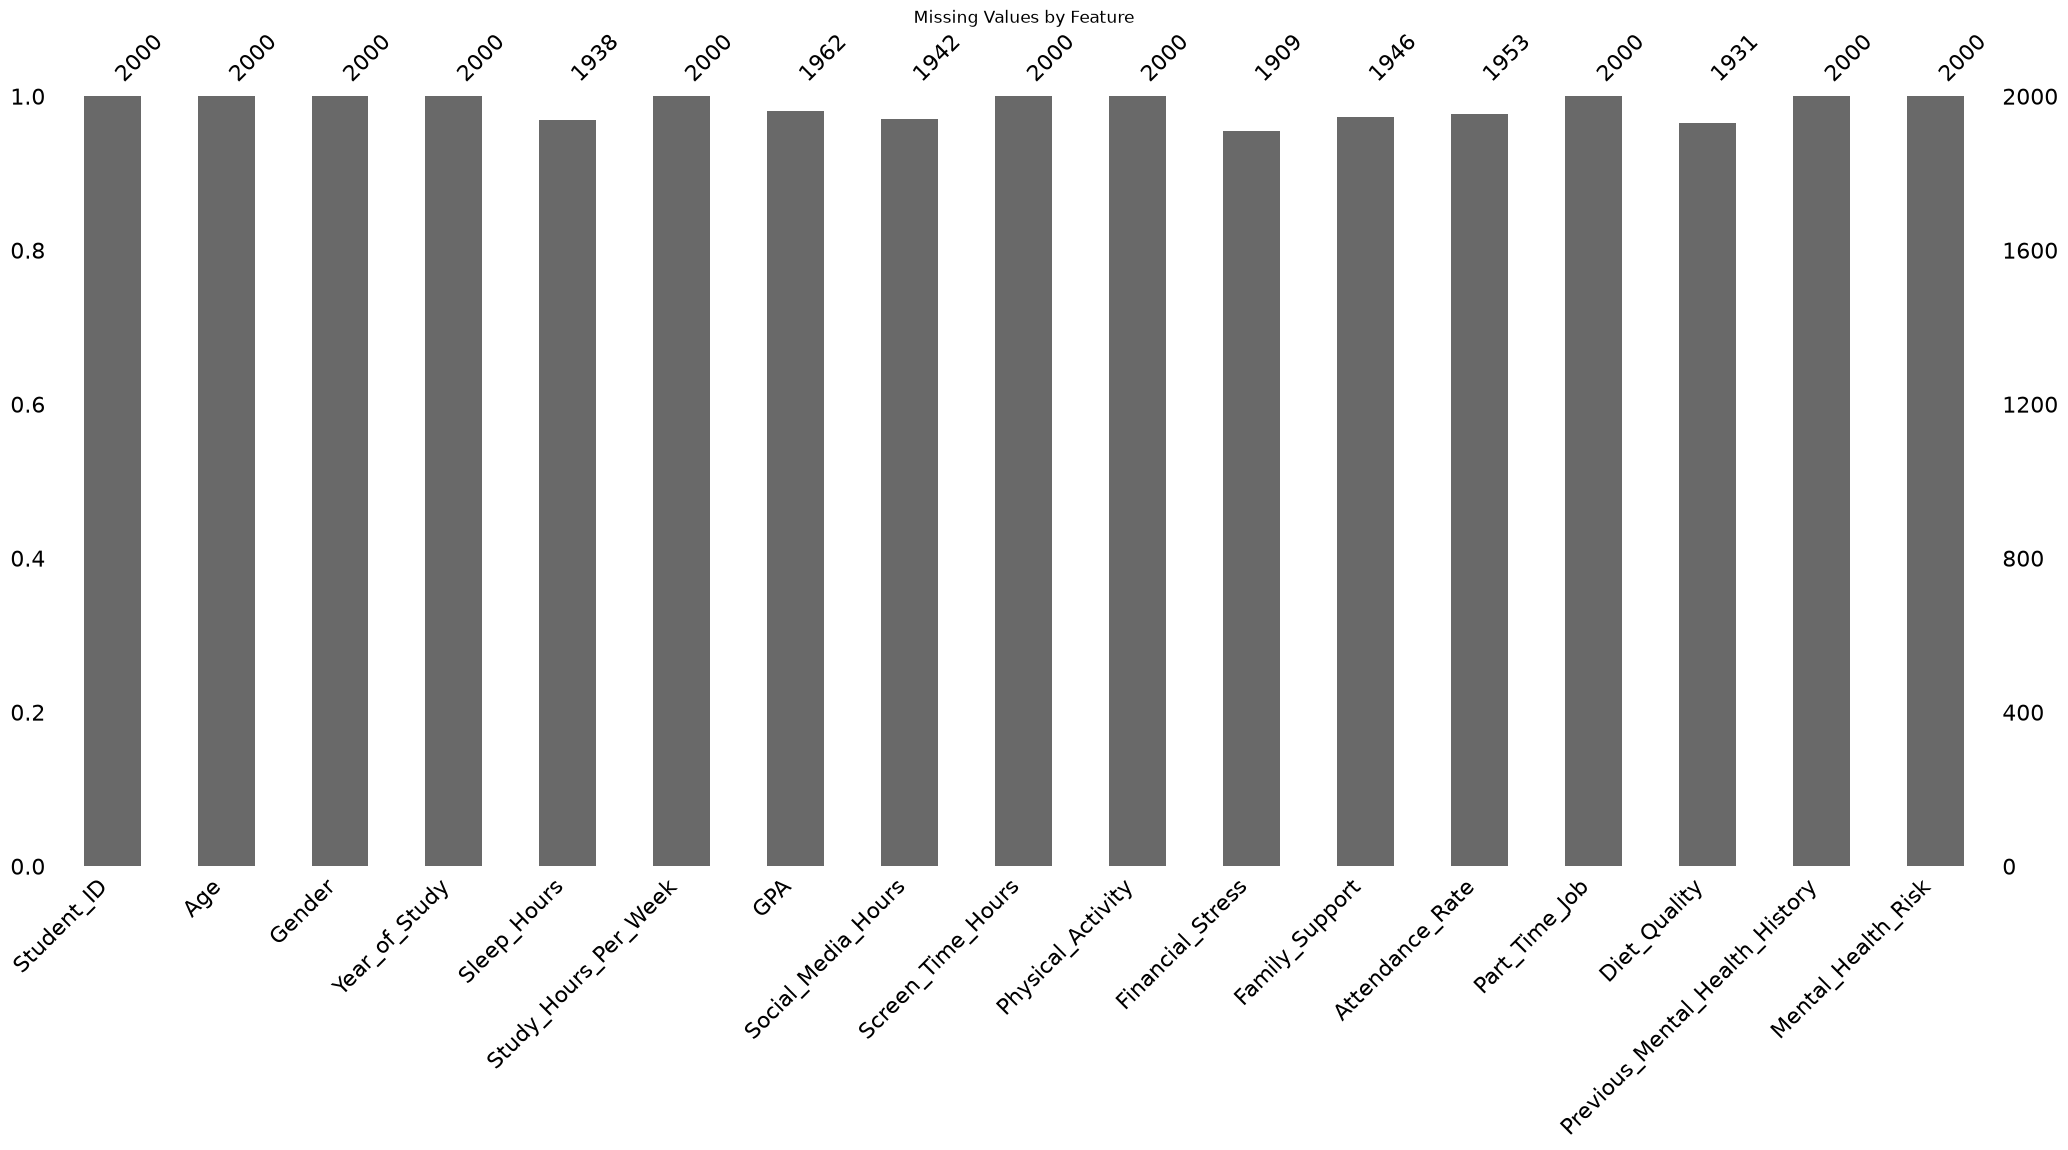

In [8]:
msno.bar(df)
plt.title("Missing Values by Feature")
plt.show()

[<BarContainer object of 7 artists>]


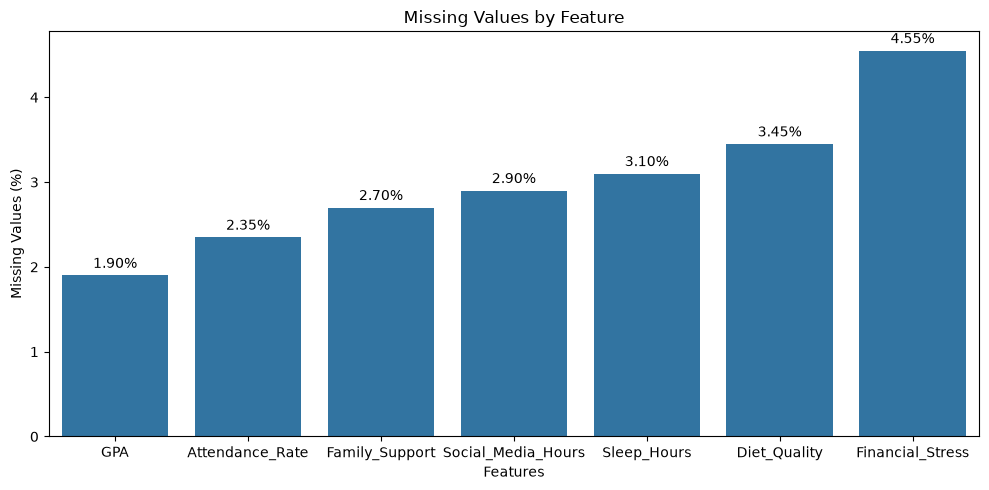

In [9]:
missing = (df.isnull().sum() / len(df) * 100)
missing = missing[missing > 0].sort_values()

plt.figure(figsize=(10, 5))

ax = sns.barplot(x=missing.index, y=missing.values)

print(ax.containers)

ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

plt.title("Missing Values by Feature")
plt.ylabel("Missing Values (%)")
plt.xlabel("Features")

plt.tight_layout()
plt.show()

### Histogrammes et boxplots

In [10]:
df.select_dtypes(include=np.number).columns

Index(['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA',
       'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress',
       'Family_Support', 'Attendance_Rate'],
      dtype='object')

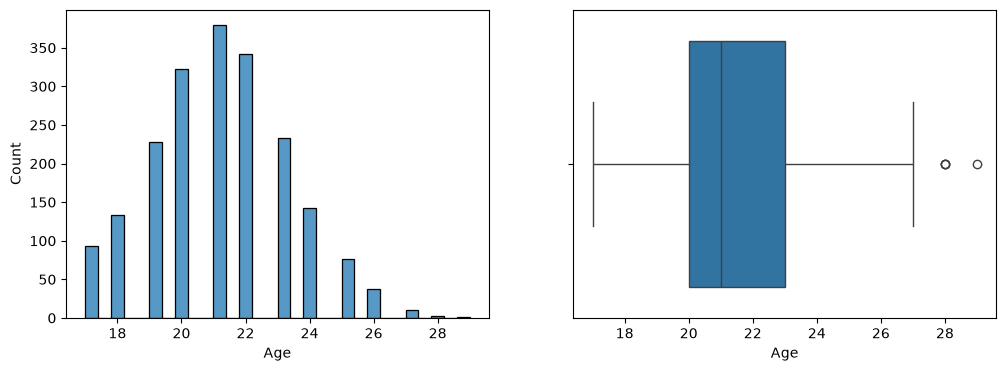

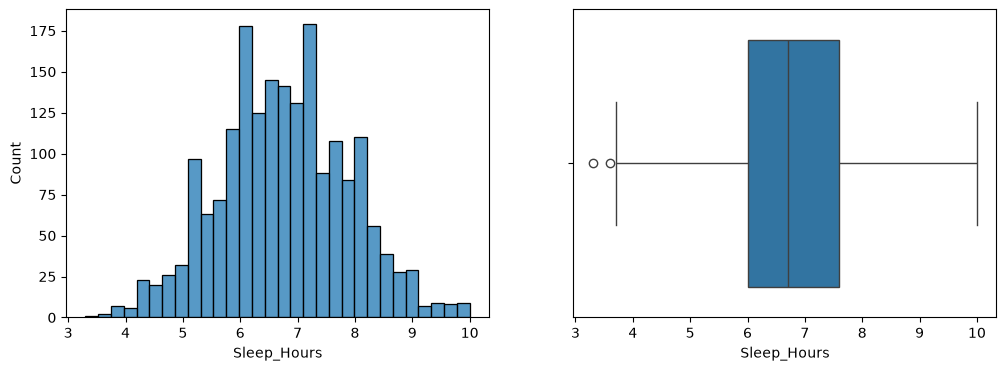

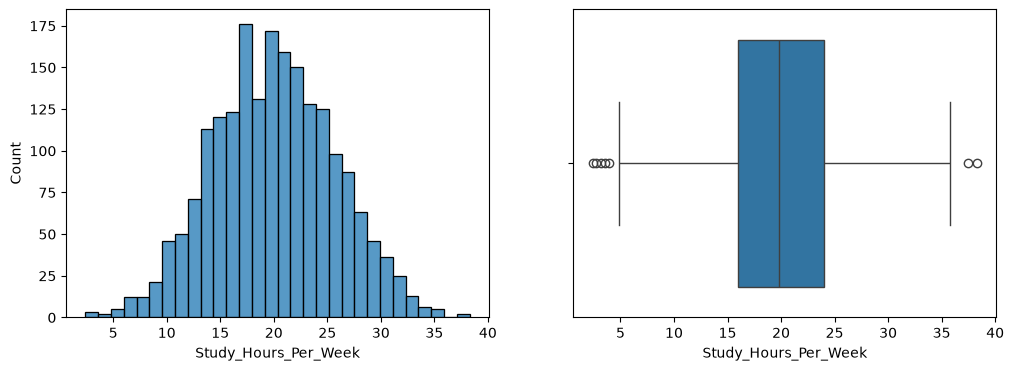

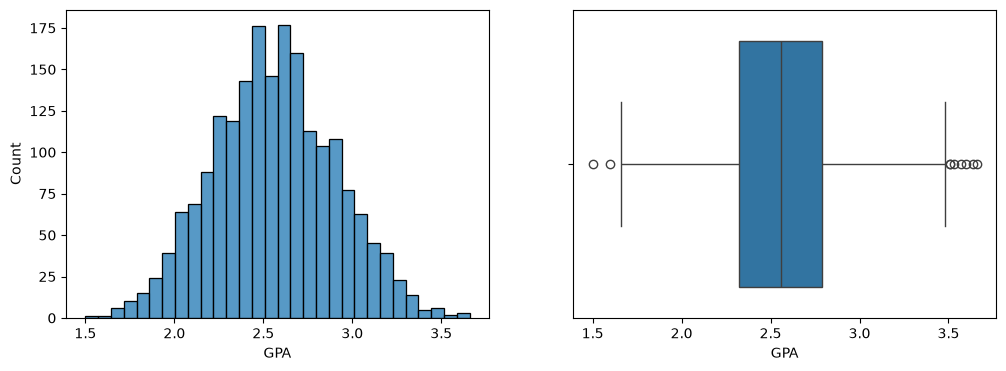

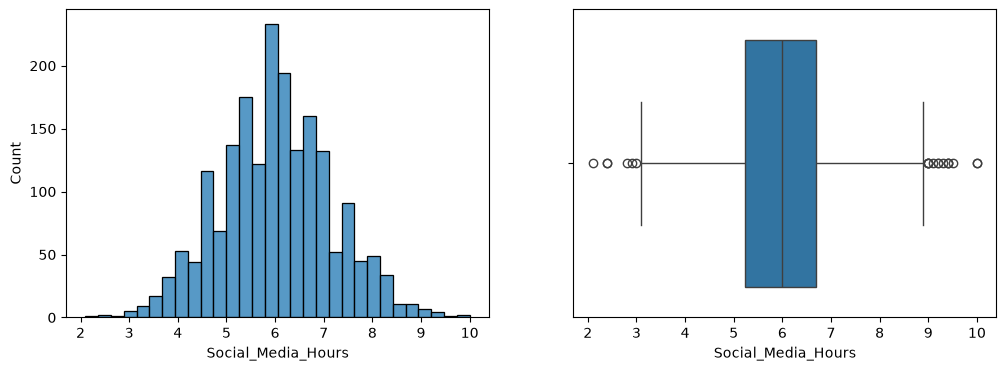

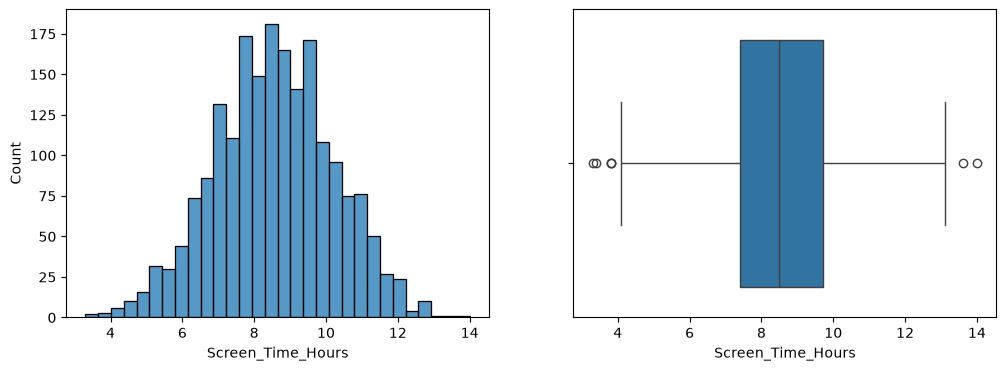

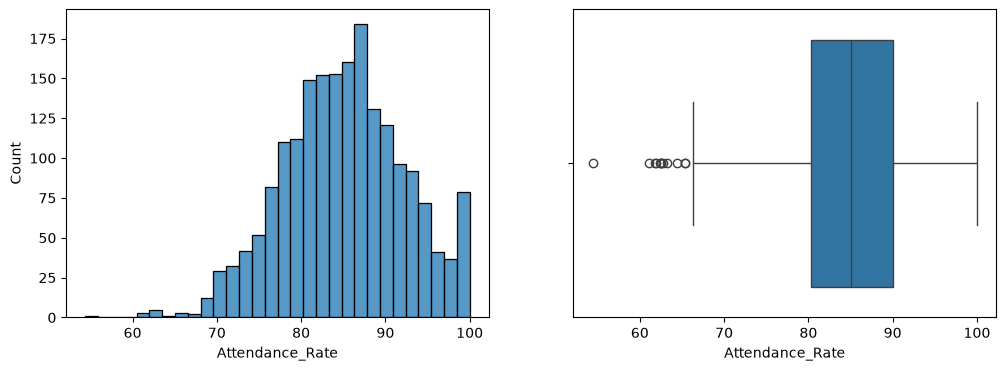

In [11]:
def boxplot_histogram(column):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.histplot(df,x=column, bins=30, ax=axes[0])
    sns.boxplot(x=df[column], ax=axes[1])
    plt.show()
numerical_columns = [
    "Age",
    "Sleep_Hours",
    "Study_Hours_Per_Week",
    "GPA",
    "Social_Media_Hours",
    "Screen_Time_Hours",
    "Attendance_Rate"
]
for column in numerical_columns:
    boxplot_histogram(column)

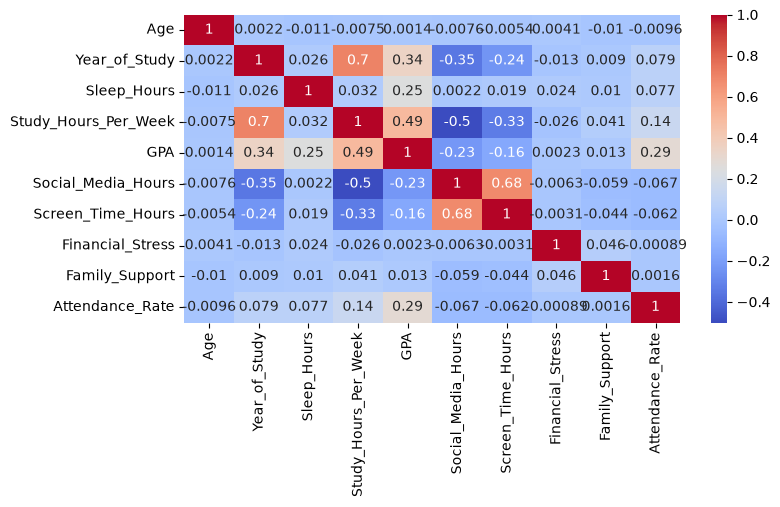

In [12]:
corr = df.select_dtypes(include=np.number).corr()
fig, ax = plt.subplots(figsize=(8,4))
sns.heatmap(corr, annot=True,cmap="coolwarm")
plt.show()

Pearson r: 0.68
Rows compared: 1942


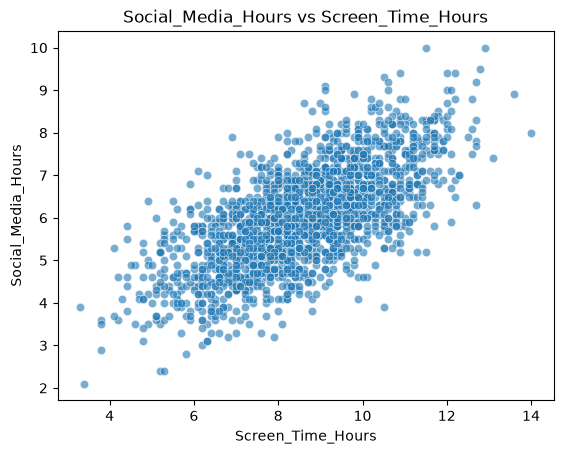

In [42]:
x = "Screen_Time_Hours"
y = "Social_Media_Hours"

pair = df[[x, y]].dropna()

print("Pearson r:", round(pair[x].corr(pair[y]), 2))
print("Rows compared:", len(pair))

# plt.scatter(pair[x], pair[y], alpha=0.3)
sns.scatterplot(df,x=pair[x],y=pair[y],alpha=0.6)
plt.xlabel(x)
plt.ylabel(y)
plt.title(f"{y} vs {x}")
plt.show()

In [28]:
profile = ProfileReport(df, title="EDA_Report")
profile.to_file(ROOT/ "repport" / "eda_report.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 17/17 [00:00<00:00, 389.38it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

### Vérifier les valeurs manquantes, les doublons, les incohérences et les valeurs aberrantes. 

In [32]:
df.select_dtypes(include=np.number).columns

Index(['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA',
       'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress',
       'Family_Support', 'Attendance_Rate'],
      dtype='object')

In [ ]:
Suspicious_age_values = (df["Age"] < 16) | (df["Age"] > 70) # Integer, positive, ≤120
Suspicious_year_of_stady_values  = (df["Year_of_Study"] <= 0) | (df["Year_of_Study"] > 6) # Positive integer, usually 1–6 
Suspicious_Sleep_Hours = (df["Sleep_Hours"] <= 0) | (df["Sleep_Hours"] < 3) | (df["Sleep_Hours"] > 12) # 0, below 3, or above 12
Suspicious_Study_Hours_Per_Week = (df["Study_Hours_Per_Week"] > 80) | (df["Study_Hours_Per_Week"] < 0) # Above 80 hours
Suspicous_GPA = (df["GPA"])

In [ ]:
age = df["Age"]
year = df["Year_of_Study"]
sleep = df["Sleep_Hours"]
study = df["Study_Hours_Per_Week"]
gpa = df["GPA"]
social = df["Social_Media_Hours"]
screen = df["Screen_Time_Hours"]
stress = df["Financial_Stress"]
support = df["Family_Support"]
attendance = df["Attendance_Rate"]

# Invalid numeric values
Invalid_age_values = age.notna() & ((age < 1) | (age > 120))
Invalid_year_of_study_values = year.notna() & ((year < 1) | (year > 5))
Invalid_Sleep_Hours = (sleep < 0) | (sleep > 24)
Invalid_Study_Hours_Per_Week = (study < 0) | (study > 168)
Invalid_GPA = (gpa < 0) | (gpa > 4)
Invalid_Social_Media_Hours = (social < 0) | (social > 24)
Invalid_Screen_Time_Hours = (screen < 0) | (screen > 24)
Invalid_Financial_Stress = (stress < 1) | (stress > 10)
Invalid_Family_Support = (support < 1) | (support > 10)
Invalid_Attendance_Rate = (attendance < 0) | (attendance > 100)

# Invalid category values
gender = df["Gender"]
activity = df["Physical_Activity"]
job = df["Part_Time_Job"]
diet = df["Diet_Quality"]
history = df["Previous_Mental_Health_History"]

Invalid_Gender = gender.notna() & ~gender.isin(["Female", "Male", "Non-binary"])
Invalid_Physical_Activity = activity.notna() & ~activity.isin(["Low", "Moderate", "High"])
Invalid_Part_Time_Job = job.notna() & ~job.isin(["Yes", "No"])
Invalid_Diet_Quality = diet.notna() & ~diet.isin(["Poor", "Average", "Good"])
Invalid_Previous_Mental_Health_History = history.notna() & ~history.isin(["Yes", "No"])

# Required ID and target
student_id = df["Student_ID"]
Invalid_Student_ID = student_id.isna() | student_id.duplicated(keep=False)
Invalid_Mental_Health_Risk = ~df["Mental_Health_Risk"].isin(["Low", "Medium", "High"])

# Values within the allowed range that are worth reviewing
Suspicious_age_values = ((age < 16) | (age > 70)) & ~Invalid_age_values
Suspicious_Sleep_Hours = ((sleep < 3) | (sleep > 12)) & ~Invalid_Sleep_Hours
Suspicious_Study_Hours_Per_Week = (study > 80) & ~Invalid_Study_Hours_Per_Week
Suspicious_Social_Media_Hours = (social > 12) & ~Invalid_Social_Media_Hours
Suspicious_Screen_Time_Hours = (screen > 18) & ~Invalid_Screen_Time_Hours
Suspicious_Attendance_Rate = (attendance < 60) & ~Invalid_Attendance_Rate

# Compare the two screen-time columns
Suspicious_Screen_Consistency = (
    (social > screen) & ~Invalid_Social_Media_Hours & ~Invalid_Screen_Time_Hours
)

In [39]:
Suspicious_Screen_Consistency.sum()

np.int64(37)